<a href="https://colab.research.google.com/github/VictorManuelOrt/Biometric/blob/main/POMDP_Biometric.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Identificación biométrica multimodal secuencial mediante control del estado de creencia

## Estudio computacional reproducible (semilla 2026)

Este cuaderno reproduce el experimento numérico presentado en la Sección 6 del manuscrito preparado para *Mathematics* (MDPI). Incluye:

- la solución de Bellman de referencia sobre una cuadrícula finita;
- la comparación de cinco políticas mediante Monte Carlo;
- las tres figuras del manuscrito;
- diagnósticos de resolución de la cuadrícula y de Gauss–Hermite;
- análisis de sensibilidad al factor de descuento;
- monotonía respecto al costo de adquisición;
- eliminación de una degradación gaussiana con mayor costo; y
- comprobaciones automáticas frente a los valores reportados en el manuscrito.

El operador numérico de Bellman utiliza cuantización del posterior y cuadratura de Gauss–Hermite. Por lo tanto, las comparaciones de cuadratura que se presentan a continuación son diagnósticos empíricos de resolución; no constituyen un certificado uniforme validado del error de integración.

### Adaptación para datos provenientes de un DataFrame real

Definimos un DataFrame de ejemplo estructurado como `(Id, source_1, source_2, source_3)`.

En lugar de utilizar diferentes sources, se emplean distintas características extraídas de una misma fuente de datos (source). Además, el costo asociado a cada característica se define como inversamente proporcional a la desviación estándar observada en los datos: a mayor variabilidad, menor costo; a menor variabilidad, mayor costo.

In [37]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
import pickle

ruta = '/content/drive/MyDrive/GaborFeatures_Dictionary003000.pkl'

with open(ruta, 'rb') as f:
    data = pickle.load(f)

print(type(data))

<class 'dict'>


In [39]:
print("Tipo de objeto:", type(data))

if isinstance(data, dict):
    print("Número de elementos:", len(data))
    print("Primeras claves:", list(data.keys())[:10])

elif isinstance(data, (list, tuple)):
    print("Número de elementos:", len(data))
    print("Primeros elementos:", data[:5])

else:
    print(data)

Tipo de objeto: <class 'dict'>
Número de elementos: 3000
Primeras claves: ['AA_1.jpg', 'AA_10.jpg', 'AA_11.jpg', 'AA_12.jpg', 'AA_13.jpg', 'AA_14.jpg', 'AA_15.jpg', 'AA_16.jpg', 'AA_17.jpg', 'AA_18.jpg']


In [40]:
import pandas as pd

df = pd.DataFrame.from_dict(data, orient='index')

display(df.head())
print("Dimensiones:", df.shape)

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
AA_1.jpg,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,66.511676,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
AA_10.jpg,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,60.695156,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
AA_11.jpg,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,65.842245,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
AA_12.jpg,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,70.937716,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
AA_13.jpg,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,70.284450,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209


Dimensiones: (3000, 24)


In [41]:
import pandas as pd

df = pd.DataFrame.from_dict(data, orient='index')

df = df.reset_index()
df = df.rename(columns={'index': 'ID'})

display(df.head())
print("Dimensiones:", df.shape)

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA_1.jpg,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA_10.jpg,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA_11.jpg,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA_12.jpg,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA_13.jpg,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209


Dimensiones: (3000, 25)


In [42]:
# 1. Extraer la clave de los dos primeros caracteres de ID
df['clave'] = df['ID'].str[:2]

# 2. Contar cuántas filas tiene cada clave
conteo = df['clave'].value_counts()

# Conservar únicamente las claves con al menos 20 filas
claves_validas = conteo[conteo >= 20].index

# 3. Filtrar y seleccionar las primeras 20 filas de cada clave
df_filtrado = (
    df[df['clave'].isin(claves_validas)]
    .groupby('clave', sort=False)
    .head(20)
    .drop(columns=['clave'])
    .reset_index(drop=True)
)

# Mostrar resultados
display(df_filtrado.head(10))
print("Dimensiones originales:", df.shape)
print("Dimensiones filtradas:", df_filtrado.shape)
print("Claves conservadas:", df_filtrado['ID'].str[:2].nunique())


,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA_1.jpg,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA_10.jpg,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA_11.jpg,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA_12.jpg,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA_13.jpg,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209
5,AA_14.jpg,105.122244,111.701282,55.851803,45.394282,203.228312,158.473937,49.819549,38.411444,63.316170,...,21.118388,16.337997,56.103034,100.154633,5.435441,3.763863,168.967466,158.888462,6.914210,6.903317
6,AA_15.jpg,100.818833,100.339309,55.587712,44.619280,210.983824,159.251737,47.255282,31.018782,65.571709,...,21.676589,16.324744,60.046415,104.121888,6.750983,3.710648,170.064531,158.082474,7.069498,5.863621
7,AA_16.jpg,89.005537,91.270046,46.015799,34.604360,201.449556,164.232430,50.957855,44.839993,52.745947,...,16.418333,14.231492,51.350953,99.067698,5.283992,3.463924,169.889492,158.525426,5.606777,5.044193
8,AA_17.jpg,107.414097,107.881801,58.243348,45.213552,202.806022,163.815410,52.877548,42.466927,65.424483,...,26.449557,24.328915,58.707766,101.204283,5.919462,5.013341,168.802881,158.501443,5.766805,5.375352
9,AA_18.jpg,94.713325,96.856897,52.694573,41.854451,198.346421,163.403870,45.705489,33.749077,62.544316,...,22.476373,18.157409,57.050770,102.159214,6.424102,5.040136,167.473559,157.937350,5.785962,4.798207


Dimensiones originales: (3000, 26)
Dimensiones filtradas: (1960, 25)
Claves conservadas: 98


In [43]:
# Crear una copia del DataFrame filtrado
DATOS = df_filtrado.copy()

# Reemplazar ID por los dos primeros caracteres
DATOS['ID'] = DATOS['ID'].str[:2]

# Mostrar resultados
display(DATOS.head(10))
print("Dimensiones de DATOS:", DATOS.shape)

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209
5,AA,105.122244,111.701282,55.851803,45.394282,203.228312,158.473937,49.819549,38.411444,63.316170,...,21.118388,16.337997,56.103034,100.154633,5.435441,3.763863,168.967466,158.888462,6.914210,6.903317
6,AA,100.818833,100.339309,55.587712,44.619280,210.983824,159.251737,47.255282,31.018782,65.571709,...,21.676589,16.324744,60.046415,104.121888,6.750983,3.710648,170.064531,158.082474,7.069498,5.863621
7,AA,89.005537,91.270046,46.015799,34.604360,201.449556,164.232430,50.957855,44.839993,52.745947,...,16.418333,14.231492,51.350953,99.067698,5.283992,3.463924,169.889492,158.525426,5.606777,5.044193
8,AA,107.414097,107.881801,58.243348,45.213552,202.806022,163.815410,52.877548,42.466927,65.424483,...,26.449557,24.328915,58.707766,101.204283,5.919462,5.013341,168.802881,158.501443,5.766805,5.375352
9,AA,94.713325,96.856897,52.694573,41.854451,198.346421,163.403870,45.705489,33.749077,62.544316,...,22.476373,18.157409,57.050770,102.159214,6.424102,5.040136,167.473559,157.937350,5.785962,4.798207


Dimensiones de DATOS: (1960, 25)


In [44]:
DATOS1=DATOS

In [45]:
DATOS1

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1955,GA,115.934535,111.405520,59.667588,50.916423,194.201925,150.722351,51.663604,35.567513,68.624029,...,21.797191,15.705812,56.519265,104.726517,5.871566,5.082087,169.371888,159.634019,6.320495,4.425193
1956,GA,142.866504,152.445735,41.244779,37.207509,201.311096,160.948375,42.619429,38.344754,86.529694,...,19.151905,19.372905,52.660622,98.319324,4.656087,4.096341,171.713397,161.347045,5.402220,3.897182
1957,GA,142.866504,152.445735,41.244779,37.207509,201.311096,160.948375,42.619429,38.344754,86.529694,...,19.151905,19.372905,52.660622,98.319324,4.656087,4.096341,171.713397,161.347045,5.402220,3.897182
1958,GA,112.170548,116.564908,48.140079,33.247473,198.394414,149.903316,58.182013,38.268881,71.880589,...,24.254335,21.936848,53.953993,104.869283,7.462140,7.082980,170.139867,160.518636,6.266833,5.128880


In [46]:
# Filtrar DATOS1 para conservar únicamente los ID: 'CH', 'DX' y 'BN'
datos_filtrados = DATOS1[DATOS1['ID'].isin(['CH', 'DX', 'BN'])].reset_index(drop=True)

# Mostrar el DataFrame resultante y su distribución de clases
display(datos_filtrados.head())
print("Dimensiones del DataFrame filtrado:", datos_filtrados.shape)
print("Conteo de filas por identidad:")
print(datos_filtrados['ID'].value_counts())

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,BN,167.110491,143.131654,47.071575,33.170880,274.198937,183.045943,50.914359,36.810637,96.868333,...,25.550407,19.706175,64.026141,100.169063,11.834387,7.266224,173.014154,160.747273,11.774612,9.970549
1,BN,124.717460,95.710168,37.767498,30.416934,260.937070,183.573763,39.603833,31.798341,80.857130,...,19.224628,15.548408,60.871957,103.802031,9.048836,5.154718,169.813789,159.935710,9.154712,5.444019
2,BN,126.193339,97.952274,38.186216,31.146718,265.817849,189.086232,39.124475,32.924956,76.987189,...,17.846321,13.960259,53.676932,102.087507,7.849496,6.261285,170.792943,161.045933,7.113394,4.803402
3,BN,120.918871,97.884489,35.843618,31.060800,266.786405,190.678086,38.829846,31.600204,76.066439,...,18.547868,14.099492,55.728535,100.826859,8.045391,6.032213,170.597555,160.613257,7.502988,4.117089
4,BN,159.250922,131.604522,51.805452,39.102588,282.190035,193.400455,55.988865,41.034740,96.221117,...,23.932049,20.236673,64.390327,104.121859,16.183073,13.382655,175.171689,158.412145,13.681227,10.177510


Dimensiones del DataFrame filtrado: (60, 25)
Conteo de filas por identidad:
ID
BN    20
CH    20
DX    20
Name: count, dtype: int64


In [47]:
# Definir el mapeo de etiquetas de texto a numéricas
mapeo_ids = {'CH': 0, 'DX': 1, 'BN': 2}

# Reemplazar los valores en la columna ID
datos_filtrados['ID'] = datos_filtrados['ID'].map(mapeo_ids)

# Mostrar el DataFrame resultante para verificar los cambios
display(datos_filtrados.head())
print("Valores únicos en ID y sus frecuencias:")
print(datos_filtrados['ID'].value_counts())

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,2,167.110491,143.131654,47.071575,33.170880,274.198937,183.045943,50.914359,36.810637,96.868333,...,25.550407,19.706175,64.026141,100.169063,11.834387,7.266224,173.014154,160.747273,11.774612,9.970549
1,2,124.717460,95.710168,37.767498,30.416934,260.937070,183.573763,39.603833,31.798341,80.857130,...,19.224628,15.548408,60.871957,103.802031,9.048836,5.154718,169.813789,159.935710,9.154712,5.444019
2,2,126.193339,97.952274,38.186216,31.146718,265.817849,189.086232,39.124475,32.924956,76.987189,...,17.846321,13.960259,53.676932,102.087507,7.849496,6.261285,170.792943,161.045933,7.113394,4.803402
3,2,120.918871,97.884489,35.843618,31.060800,266.786405,190.678086,38.829846,31.600204,76.066439,...,18.547868,14.099492,55.728535,100.826859,8.045391,6.032213,170.597555,160.613257,7.502988,4.117089
4,2,159.250922,131.604522,51.805452,39.102588,282.190035,193.400455,55.988865,41.034740,96.221117,...,23.932049,20.236673,64.390327,104.121859,16.183073,13.382655,175.171689,158.412145,13.681227,10.177510


Valores únicos en ID y sus frecuencias:
ID
2    20
0    20
1    20
Name: count, dtype: int64


In [48]:
# Seleccionar la columna 'ID' junto con las columnas de características 0, 2 y 4
datos_filtrados = datos_filtrados[['ID', 0, 2, 4]]

# Renombrar las columnas 0, 2 y 4 a '1', '2' y '3' respectivamente
datos_filtrados = datos_filtrados.rename(columns={0: '1', 2: '2', 4: '3'})

# Mostrar el resultado final para verificar el filtro y los nuevos nombres de columnas
display(datos_filtrados.head())
print("Columnas en el DataFrame final:", datos_filtrados.columns.tolist())
print("Dimensiones finales:", datos_filtrados.shape)

,ID,1,2,3
0,2,167.110491,47.071575,274.198937
1,2,124.717460,37.767498,260.937070
2,2,126.193339,38.186216,265.817849
3,2,120.918871,35.843618,266.786405
4,2,159.250922,51.805452,282.190035


Columnas en el DataFrame final: ['ID', '1', '2', '3']
Dimensiones finales: (60, 4)


In [49]:
df = datos_filtrados


In [50]:
print(df.columns.tolist())
print(df.dtypes)
print(df["ID"].value_counts())

['ID', '1', '2', '3']
ID      int64
1     float64
2     float64
3     float64
dtype: object
ID
2    20
0    20
1    20
Name: count, dtype: int64


In [51]:
# Calcular las desviaciones estándar de las columnas '1', '2' y '3' agrupadas por 'ID'
desviaciones_por_id = df.groupby('ID')[['1', '2', '3']].std(ddof=1)

print("Desviaciones estándar por cada ID (ddof=1):")
display(desviaciones_por_id)

Desviaciones estándar por cada ID (ddof=1):


,1,2,3
ID,,,
0,7.688443,3.987945,7.902078
1,4.341275,3.016243,16.915130
2,19.936915,7.899223,10.871214


In [52]:
SOURCE_COLS = ['1', '2', '3']   # si los nombres son strings: ["1", "2", "3"]

# bank[fuente][identidad] -> array con los valores reales
bank = [
    [df.loc[df["ID"] == k, c].to_numpy(float) for k in range(3)]
    for c in SOURCE_COLS
]

def draw_real(rng, source, true_ids):
    """Sortea con reemplazo, de las filas de la misma identidad, la columna de la fuente."""
    true_ids = np.asarray(true_ids)
    out = np.empty(len(true_ids))
    for k in range(3):
        m = true_ids == k
        if m.any():
            out[m] = rng.choice(bank[source][k], size=int(m.sum()), replace=True)
    return out

In [53]:
import json
import platform
import sys
from math import pi, sqrt
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from matplotlib.lines import Line2D
from numpy.polynomial.hermite import hermgauss
from scipy.spatial import cKDTree

try:
    from IPython import get_ipython
    from IPython.display import display

    shell = get_ipython()
    if shell is not None:
        shell.run_line_magic("matplotlib", "inline")
except ImportError:
    display = None

print(f"Python {platform.python_version()}")
print(f"NumPy {np.__version__}")
print(f"SciPy {scipy.__version__}")
print(f"pandas {pd.__version__}")
print(f"Matplotlib {matplotlib.__version__}")



Python 3.13.18
NumPy 2.1.3
SciPy 1.16.3
pandas 2.2.3
Matplotlib 3.10.0


In [54]:
#MU = np.array(
#    [
#        [-1.50, 0.00, 0.40],
#        [-0.40, 0.00, 1.50],
#        [-1.00, 0.00, 1.00],
#    ],
#    dtype=float,
#)
#SIGMA = np.array([0.45, 0.45, 0.75], dtype=float)

MU = np.array([[df.loc[df["ID"] == k, c].mean() for k in range(3)]
               for c in SOURCE_COLS])               # forma (3 fuentes, 3 identidades)

SIGMA = np.array([
    np.sqrt(np.mean([df.loc[df["ID"] == k, c].var(ddof=1) for k in range(3)]))
    for c in SOURCE_COLS
])                                                    # desviación pooled por fuente


COST = np.array([0.045, 0.055, 0.020], dtype=float)
BETA = 0.98
P0 = np.full(3, 1.0 / 3.0)
SEED = 2026
IDENTITY_SEED, OBSERVATION_SEED = np.random.SeedSequence(SEED).spawn(2)
N_SIMULATIONS = 50_000
T_MAX = 100

OUTPUT_DIR = Path("notebook_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


def show_table(table):
    """Display a DataFrame in a notebook and print it in a plain script."""
    if display is None:
        print(table.to_string(index=False))
    else:
        display(table)


parameter_table = pd.DataFrame(
    {
        "source": [1, 2, 3],
        "mu_1": MU[:, 0],
        "mu_2": MU[:, 1],
        "mu_3": MU[:, 2],
        "sigma": SIGMA,
        "cost": COST,
    }
)
show_table(parameter_table)



,source,mu_1,mu_2,mu_3,sigma,cost
0,1,74.584028,112.212785,149.343760,12.588876,0.045
1,2,31.566894,46.859585,45.235554,5.397504,0.055
2,3,232.932575,228.773929,274.295690,12.473275,0.020


In [55]:
def simplex_grid(M):
    """Regular grid on the three-dimensional probability simplex."""
    return np.array(
        [
            (i / M, j / M, (M - i - j) / M)
            for i in range(M + 1)
            for j in range(M - i + 1)
        ],
        dtype=float,
    )


class Model:
    """Quadrature-discretized belief-state stopping model for K=3."""

    def __init__(
        self,
        M=30,
        R=15,
        mu=MU,
        sigma=SIGMA,
        cost=COST,
        beta=BETA,
        p0=P0,
    ):
        self.M = int(M)
        self.R = int(R)
        self.mu = np.asarray(mu, dtype=float)
        self.sigma = np.asarray(sigma, dtype=float)
        self.cost = np.asarray(cost, dtype=float)
        self.beta = float(beta)
        self.p0 = np.asarray(p0, dtype=float)
        self.K = self.mu.shape[1]
        self.n_sources = self.mu.shape[0]

        if self.K != 3:
            raise ValueError("This numerical grid implementation requires K=3.")
        if self.sigma.shape != (self.n_sources,):
            raise ValueError("sigma must contain one entry per source.")
        if self.cost.shape != (self.n_sources,):
            raise ValueError("cost must contain one entry per source.")
        if not (0.0 < self.beta < 1.0):
            raise ValueError("beta must lie in (0,1).")

        self.grid = simplex_grid(self.M)
        self.tree = cKDTree(self.grid)
        self.stop_cost = 1.0 - self.grid
        self.nodes, raw_weights = hermgauss(self.R)
        self.weights = raw_weights / sqrt(pi)
        self.next_state, self.mixture_weights = self._transitions()

    def project(self, belief):
        """Nearest-neighbor projection onto the regular belief grid."""
        return np.asarray(self.tree.query(belief)[1], dtype=int)

    def update(self, belief, observation, source):
        """Exact Bayesian update before belief quantization."""
        observation = np.asarray(observation)
        log_likelihood = -0.5 * (
            (observation[..., None] - self.mu[source]) / self.sigma[source]
        ) ** 2
        likelihood = np.exp(
            log_likelihood - log_likelihood.max(axis=-1, keepdims=True)
        )
        numerator = belief * likelihood
        return numerator / numerator.sum(axis=-1, keepdims=True)

    def _transitions(self):
        """Projected posteriors and predictive quadrature weights."""
        true_identity = np.repeat(np.arange(self.K), self.R)
        node_index = np.tile(np.arange(self.R), self.K)
        mixture_weights = (
            self.grid[:, true_identity] * self.weights[node_index]
        )
        next_state = np.empty(
            (
                self.n_sources,
                len(self.grid),
                self.K * self.R,
            ),
            dtype=int,
        )

        for source in range(self.n_sources):
            observations = (
                self.mu[source, true_identity]
                + sqrt(2.0) * self.sigma[source] * self.nodes[node_index]
            )
            log_likelihood = -0.5 * (
                (observations[:, None] - self.mu[source])
                / self.sigma[source]
            ) ** 2
            likelihood = np.exp(
                log_likelihood - log_likelihood.max(axis=1, keepdims=True)
            )
            numerator = self.grid[:, None, :] * likelihood[None, :, :]
            posterior = numerator / numerator.sum(axis=2, keepdims=True)
            next_state[source] = self.project(
                posterior.reshape(-1, self.K)
            ).reshape(len(self.grid), -1)

        return next_state, mixture_weights

    def action_values(self, value):
        """Stopping and observation action values at every grid point."""
        observe = np.empty((len(self.grid), self.n_sources))
        for source in range(self.n_sources):
            continuation = np.sum(
                self.mixture_weights * value[self.next_state[source]],
                axis=1,
            )
            observe[:, source] = (
                self.cost[source] + self.beta * continuation
            )
        return np.column_stack((self.stop_cost, observe))

    def solve(self, tolerance=1e-10, max_iterations=10_000):
        """Value iteration with a contraction-based a posteriori error bound."""
        value = self.stop_cost.min(axis=1)
        error_bound = np.inf
        for iteration in range(1, max_iterations + 1):
            action_values = self.action_values(value)
            new_value = action_values.min(axis=1)
            error_bound = (
                self.beta
                * np.max(np.abs(new_value - value))
                / (1.0 - self.beta)
            )
            value = new_value
            if error_bound <= tolerance:
                break
        else:
            raise RuntimeError("Value iteration did not converge.")

        action_values = self.action_values(value)
        policy = np.argmin(action_values, axis=1)
        return value, policy, iteration, float(error_bound)


baseline_model = Model(M=30, R=15)
baseline_value, baseline_policy, iterations, iteration_error = (
    baseline_model.solve()
)
p0_index = int(baseline_model.project(P0))

baseline_summary = pd.DataFrame(
    {
        "quantity": [
            "number of grid points",
            "value at p0",
            "initial action index",
            "initial action",
            "iterations",
            "a posteriori iteration bound",
        ],
        "value": [
            str(len(baseline_model.grid)),
            f"{baseline_value[p0_index]:.12f}",
            str(int(baseline_policy[p0_index])),
            "source 3",
            str(iterations),
            f"{iteration_error:.3e}",
        ],
    }
)
show_table(baseline_summary)



,quantity,value
0,number of grid points,496
1,value at p0,0.065086025881
2,initial action index,3
3,initial action,source 3
4,iterations,18
5,a posteriori iteration bound,5.603e-11


In [56]:
def myopic_actions(beliefs, model):
    """One-step look-ahead policy using the same quadrature rule."""
    observe = np.empty((len(beliefs), model.n_sources))
    for source in range(model.n_sources):
        expected_terminal_loss = np.zeros(len(beliefs))
        for identity in range(model.K):
            for node, weight in zip(model.nodes, model.weights):
                observation = (
                    model.mu[source, identity]
                    + sqrt(2.0) * model.sigma[source] * node
                )
                posterior = model.update(
                    beliefs,
                    np.full(len(beliefs), observation),
                    source,
                )
                expected_terminal_loss += (
                    beliefs[:, identity]
                    * weight
                    * (1.0 - posterior.max(axis=1))
                )
        observe[:, source] = (
            model.cost[source]
            + model.beta * expected_terminal_loss
        )
    return np.argmin(
        np.column_stack((1.0 - beliefs, observe)),
        axis=1,
    )


def simulate(
    policy_name,
    model,
    grid_policy,
    identities,
    seed=OBSERVATION_SEED,
    t_max=T_MAX,
):
    """Simulate one policy on exact, unquantized posterior beliefs."""
    n = len(identities)
    rng = np.random.default_rng(seed)
    belief = np.tile(model.p0, (n, 1))
    active = np.ones(n, dtype=bool)
    objective = np.zeros(n)
    observations = np.zeros(n, dtype=int)
    raw_acquisition = np.zeros(n)
    discounted_acquisition = np.zeros(n)
    terminal_loss = np.zeros(n)
    source_counts = np.zeros(model.n_sources, dtype=int)
    correct = np.zeros(n, dtype=bool)
    predictions = np.full(n, -1, dtype=int)

    for t in range(t_max):
        active_ids = np.flatnonzero(active)
        if not len(active_ids):
            break
        current_belief = belief[active_ids]

        if policy_name == "grid":
            action = grid_policy[model.project(current_belief)]
        elif policy_name == "map":
            action = np.argmax(current_belief, axis=1)
        elif policy_name == "all_once":
            action = np.where(
                observations[active_ids] < model.n_sources,
                model.K + observations[active_ids],
                np.argmax(current_belief, axis=1),
            )
        elif policy_name == "cheapest":
            cheapest_source = int(np.argmin(model.cost))
            action = np.where(
                current_belief.max(axis=1) >= 0.95,
                np.argmax(current_belief, axis=1),
                model.K + cheapest_source,
            )
        elif policy_name == "myopic":
            action = myopic_actions(current_belief, model)
        else:
            raise ValueError(f"Unknown policy: {policy_name}")

        stopping = action < model.K
        stopping_ids = active_ids[stopping]
        declared = action[stopping]
        predictions[stopping_ids] = declared
        correct[stopping_ids] = declared == identities[stopping_ids]
        loss = model.beta**t * (
            declared != identities[stopping_ids]
        )
        objective[stopping_ids] += loss
        terminal_loss[stopping_ids] += loss
        active[stopping_ids] = False

        for source in range(model.n_sources):
            selected = action == model.K + source
            observation_ids = active_ids[selected]
            if not len(observation_ids):
                continue
            discounted_cost = model.beta**t * model.cost[source]
            objective[observation_ids] += discounted_cost
            discounted_acquisition[observation_ids] += discounted_cost
            raw_acquisition[observation_ids] += model.cost[source]
            observations[observation_ids] += 1
            source_counts[source] += len(observation_ids)
            #scores = rng.normal(
            #    model.mu[source, identities[observation_ids]],
            #    model.sigma[source],
            #)
            scores = draw_real(rng, source, identities[observation_ids])
            belief[observation_ids] = model.update(
                belief[observation_ids],
                scores,
                source,
            )

    remaining_ids = np.flatnonzero(active)
    if len(remaining_ids):
        declared = np.argmax(belief[remaining_ids], axis=1)
        predictions[remaining_ids] = declared
        correct[remaining_ids] = declared == identities[remaining_ids]
        loss = model.beta**t_max * (
            declared != identities[remaining_ids]
        )
        objective[remaining_ids] += loss
        terminal_loss[remaining_ids] += loss
        active[remaining_ids] = False

    confusion = np.zeros((model.K, model.K), dtype=int)
    np.add.at(confusion, (identities, predictions), 1)
    tp = np.diag(confusion).astype(float)
    precision = np.divide(tp, confusion.sum(axis=0), out=np.zeros(model.K), where=confusion.sum(axis=0)>0)
    recall = np.divide(tp, confusion.sum(axis=1), out=np.zeros(model.K), where=confusion.sum(axis=1)>0)
    f1 = np.divide(2*precision*recall, precision+recall, out=np.zeros(model.K), where=precision+recall>0)
    total_source_count = source_counts.sum()
    source_fractions = (
        source_counts / total_source_count
        if total_source_count
        else np.zeros(model.n_sources)
    )
    return {
        "policy": policy_name,
        "macro_precision": float(precision.mean()),
        "macro_recall": float(recall.mean()),
        "macro_f1": float(f1.mean()),
        "confusion_matrix": confusion.tolist(),
        "per_class_precision": precision.tolist(),
        "per_class_recall": recall.tolist(),
        "per_class_f1": f1.tolist(),
        "objective": float(objective.mean()),
        "standard_error": float(objective.std(ddof=1) / sqrt(n)),
        "accuracy": float(correct.mean()),
        "mean_observations": float(observations.mean()),
        "mean_raw_acquisition_cost": float(raw_acquisition.mean()),
        "mean_discounted_acquisition": float(
            discounted_acquisition.mean()
        ),
        "mean_discounted_terminal_loss": float(terminal_loss.mean()),
        "source_fractions": source_fractions.tolist(),
        "safeguard_activations": int(len(remaining_ids)),
    }


identities = np.random.default_rng(IDENTITY_SEED).integers(
    0,
    baseline_model.K,
    N_SIMULATIONS,
)
policy_names = ["grid", "map", "all_once", "cheapest", "myopic"]
simulation_results = [
    simulate(
        name,
        baseline_model,
        baseline_policy,
        identities,
        seed=OBSERVATION_SEED,
    )
    for name in policy_names
]

policy_labels = {
    "grid": "Grid policy",
    "map": "Immediate MAP",
    "all_once": "All sources once",
    "cheapest": "Cheapest source to 0.95",
    "myopic": "Myopic",
}
comparison_table = pd.DataFrame(
    [
        {
            "Policy": policy_labels[result["policy"]],
            "Objective": result["objective"],
            "SE": result["standard_error"],
            "Accuracy": result["accuracy"],
            "Macro precision": result["macro_precision"],
            "Macro recall": result["macro_recall"],
            "Macro F1": result["macro_f1"],
            "Mean obs.": result["mean_observations"],
            "Mean raw acq. cost": result[
                "mean_raw_acquisition_cost"
            ],
        }
        for result in simulation_results
    ]
)
show_table(comparison_table.round(6))

grid_result = simulation_results[0]
print("Grid-policy discounted components:")
print(
    f"  acquisition = {grid_result['mean_discounted_acquisition']:.8f}"
)
print(
    f"  terminal loss = {grid_result['mean_discounted_terminal_loss']:.8f}"
)
print(
    "  source fractions = "
    + ", ".join(f"{100*x:.2f}%" for x in grid_result["source_fractions"])
)
print(f"  safeguard activations = {grid_result['safeguard_activations']}")



,Policy,Objective,SE,Accuracy,Macro precision,Macro recall,Macro F1,Mean obs.,Mean raw acq. cost
0,Grid policy,0.059204,0.000145,0.99924,0.999239,0.999238,0.999238,1.54786,0.058793
1,Immediate MAP,0.667620,0.002107,0.33238,0.110793,0.333333,0.166309,0.00000,0.000000
2,All sources once,0.123774,0.000326,0.99398,0.994069,0.993996,0.993991,3.00000,0.120000
3,Cheapest source to 0.95,0.404438,0.001446,0.94532,0.951867,0.945150,0.944831,30.96220,0.619244
4,Myopic,0.051770,0.000137,0.99924,0.999239,0.999238,0.999238,1.23880,0.051183


Grid-policy discounted components:
  acquisition = 0.05847372
  terminal loss = 0.00072990
  source fractions = 71.93%, 0.00%, 28.07%
  safeguard activations = 0


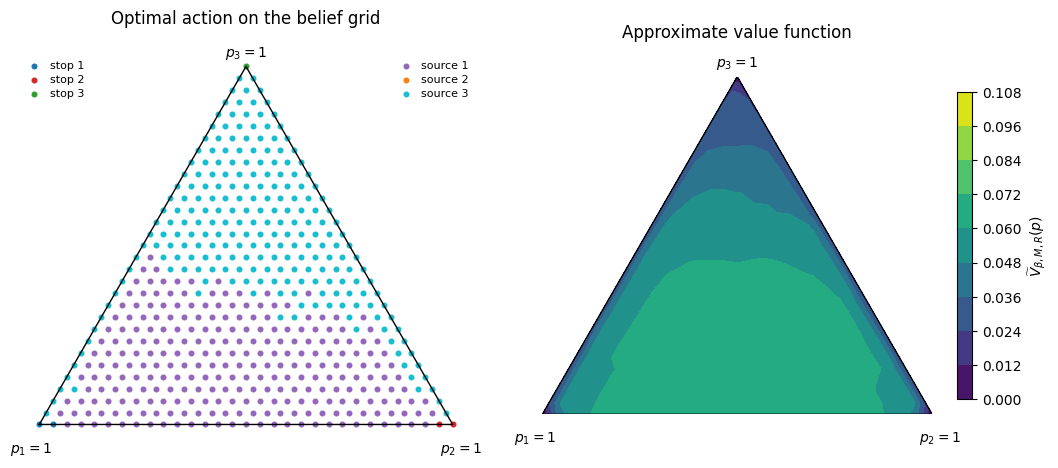

In [57]:
def triangle_coordinates(beliefs):
    """Map (p1,p2,p3) to Cartesian simplex coordinates."""
    beliefs = np.asarray(beliefs)
    x_coordinate = beliefs[:, 1] + 0.5 * beliefs[:, 2]
    y_coordinate = (sqrt(3.0) / 2.0) * beliefs[:, 2]
    return x_coordinate, y_coordinate


def add_simplex_outline(axis):
    vertices = np.array(
        [
            [0.0, 0.0],
            [1.0, 0.0],
            [0.5, sqrt(3.0) / 2.0],
            [0.0, 0.0],
        ]
    )
    axis.plot(vertices[:, 0], vertices[:, 1], color="black", lw=1.0)
    axis.text(-0.02, -0.04, r"$p_1=1$", ha="center", va="top")
    axis.text(1.02, -0.04, r"$p_2=1$", ha="center", va="top")
    axis.text(0.5, sqrt(3.0) / 2.0 + 0.025, r"$p_3=1$", ha="center")
    axis.set_aspect("equal")
    axis.axis("off")


x_grid, y_grid = triangle_coordinates(baseline_model.grid)
action_colors = [
    "tab:blue",
    "tab:red",
    "tab:green",
    "tab:purple",
    "tab:orange",
    "tab:cyan",
]
action_labels = [
    "stop 1",
    "stop 2",
    "stop 3",
    "source 1",
    "source 2",
    "source 3",
]

figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.6))
for action_index, (color, label) in enumerate(
    zip(action_colors, action_labels)
):
    selected = baseline_policy == action_index
    axes[0].scatter(
        x_grid[selected],
        y_grid[selected],
        s=11,
        color=color,
        label=label,
    )
add_simplex_outline(axes[0])
#axes[0].set_title("Optimal action on the belief grid", pad=28)
#axes[0].legend(ncol=2, fontsize=8, frameon=False, loc="upper center")
axes[0].set_title("Optimal action on the belief grid", pad=18)

handles, labels = axes[0].get_legend_handles_labels()

# Decisiones de parada: esquina superior izquierda
stop_legend = axes[0].legend(
    handles=handles[:3],
    labels=labels[:3],
    loc="upper left",
    bbox_to_anchor=(0.00, 0.98),
    fontsize=8,
    frameon=False,
    handletextpad=0.4,
    labelspacing=0.35,
    borderaxespad=0.0,
)
axes[0].add_artist(stop_legend)

# Fuentes biométricas: esquina superior derecha
axes[0].legend(
    handles=handles[3:],
    labels=labels[3:],
    loc="upper right",
    bbox_to_anchor=(1.00, 0.98),
    fontsize=8,
    frameon=False,
    handletextpad=0.4,
    labelspacing=0.35,
    borderaxespad=0.0,
)

value_levels = np.linspace(0.0, 0.108, 10)
contour = axes[1].tricontourf(
    x_grid,
    y_grid,
    baseline_value,
    levels=value_levels,
    cmap="viridis",
)
add_simplex_outline(axes[1])
axes[1].set_title("Approximate value function", pad=28)
colorbar = figure.colorbar(contour, ax=axes[1], shrink=0.78)
colorbar.set_ticks(value_levels)
colorbar.set_label(r"$\widetilde V_{\beta,M,R}(p)$")
figure.tight_layout()
figure.savefig(
    OUTPUT_DIR / "policy_and_value.pdf",
    bbox_inches="tight",
)
plt.show()



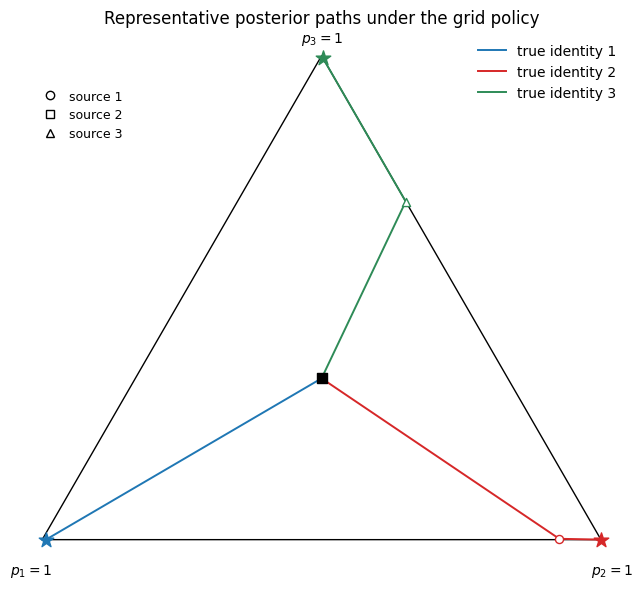

In [61]:
def simulate_single_path(
    model,
    grid_policy,
    true_identity,
    seed,
    t_max=T_MAX,
):
    """Simulate one exact-posterior path under the nearest-grid policy."""
    rng = np.random.default_rng(seed)
    belief = model.p0.copy()
    beliefs = [belief.copy()]
    actions = []

    for _ in range(t_max):
        action = int(grid_policy[int(model.project(belief))])
        actions.append(action)
        if action < model.K:
            return np.array(beliefs), actions
        source = action - model.K
        #score = rng.normal(
        #    model.mu[source, true_identity],
        #    model.sigma[source],
        #)
        score = draw_real(rng, source, [true_identity])[0]
        belief = model.update(belief, score, source)
        beliefs.append(belief.copy())

    actions.append(int(np.argmax(belief)))
    return np.array(beliefs), actions


path_settings = [(0, 2028), (1, 2026), (2, 2026)]
path_colors = ["tab:blue", "tab:red", "seagreen"]
source_markers = ["o", "s", "^"]

figure, axis = plt.subplots(figsize=(7.0, 6.0))
add_simplex_outline(axis)
for (true_identity, path_seed), color in zip(path_settings, path_colors):
    path_beliefs, path_actions = simulate_single_path(
        baseline_model,
        baseline_policy,
        true_identity,
        path_seed,
    )
    x_path, y_path = triangle_coordinates(path_beliefs)
    axis.plot(
        x_path,
        y_path,
        color=color,
        lw=1.4,
        label=f"true identity {true_identity + 1}",
    )
    for step, action in enumerate(path_actions[:-1]):
        source = action - baseline_model.K
        axis.scatter(
            x_path[step],
            y_path[step],
            marker=source_markers[source],
            s=34,
            facecolor="white",
            edgecolor=color,
            zorder=3,
        )
    axis.scatter(
        x_path[-1],
        y_path[-1],
        marker="*",
        s=120,
        color=color,
        zorder=4,
    )

x0, y0 = triangle_coordinates(P0[None, :])
axis.scatter(x0, y0, marker="s", s=48, color="black", zorder=5)
source_handles = [
    Line2D(
        [0],
        [0],
        marker=marker,
        color="none",
        markerfacecolor="white",
        markeredgecolor="black",
        label=f"source {source + 1}",
    )
    for source, marker in enumerate(source_markers)
]
identity_legend = axis.legend(
    loc="upper right",
    frameon=False,
)
axis.add_artist(identity_legend)
#axis.legend(handles=source_handles, loc="lower center", ncol=3, frameon=False,)
axis.legend(
    handles=source_handles,
    loc="upper left",
    bbox_to_anchor=(0.03, 0.90),
    ncol=1,
    fontsize=9,
    frameon=False,
    handletextpad=0.5,
    labelspacing=0.45,
    borderaxespad=0.0,
)
axis.set_title("Representative posterior paths under the grid policy")
figure.tight_layout()
figure.savefig(
    OUTPUT_DIR / "posterior_paths.pdf",
    bbox_inches="tight",
)
plt.show()



In [59]:
#Trabajar en Adelante

In [60]:
grid_sizes = [15, 30, 45, 60]
quadrature_orders = [11, 15, 21, 31]
resolution_rows = []

for M in grid_sizes:
    row = {
        "M": M,
        "N_M": (M + 1) * (M + 2) // 2,
    }
    for R in quadrature_orders:
        model = Model(M=M, R=R)
        value, policy, _, _ = model.solve()
        initial_index = int(model.project(P0))
        row[f"R={R}"] = float(value[initial_index])
        assert int(policy[initial_index]) == 5
    resolution_rows.append(row)

resolution_table = pd.DataFrame(resolution_rows)
show_table(resolution_table.round(6))

AssertionError: 

In [ ]:
beta_rows = []
for beta in [0.950, 0.980, 0.995]:
    model = Model(M=30, R=15, beta=beta)
    value, policy, _, _ = model.solve()
    result = simulate(
        "grid",
        model,
        policy,
        identities,
        seed=OBSERVATION_SEED,
    )
    beta_rows.append(
        {
            "beta": beta,
            "grid value at p0": value[int(model.project(P0))],
            "simulated objective": result["objective"],
            "standard error": result["standard_error"],
            "accuracy": result["accuracy"],
            "macro precision": result["macro_precision"],
            "macro recall": result["macro_recall"],
            "macro F1": result["macro_f1"],
            "mean observations": result["mean_observations"],
            "initial action": int(policy[int(model.project(P0))]),
        }
    )

beta_table = pd.DataFrame(beta_rows)
show_table(beta_table.round(6))

In [ ]:
c_max = float(COST.max())
loss_bound = 1.0
B_beta = max(loss_bound, c_max / (1.0 - BETA))
L_beta = sqrt(3.0) * B_beta / 2.0
mesh_bound = sqrt(3.0) / 30.0
value_error_bound = L_beta * mesh_bound / (1.0 - BETA)
policy_loss_bound = (
    2.0 * L_beta * mesh_bound / (1.0 - BETA) ** 2
)

bound_table = pd.DataFrame(
    {
        "quantity": [
            "B_beta",
            "L_beta",
            "mesh upper bound",
            "value-error bound",
            "policy-loss bound",
        ],
        "value": [
            B_beta,
            L_beta,
            mesh_bound,
            value_error_bound,
            policy_loss_bound,
        ],
    }
)
show_table(bound_table)
threshold_table = pd.DataFrame([{"M": m, "grid points": (m+1)*(m+2)//2, "value bound": 206.25/m, "policy bound": 20625/m} for m in [30,310,7501]])
show_table(threshold_table)


In [ ]:
cost_multipliers = np.array([0.75, 1.00, 1.25, 1.50, 2.00])
stopping_fractions = []
initial_values = []

for multiplier in cost_multipliers:
    model = Model(M=30, R=15, cost=multiplier * COST)
    value, policy, _, _ = model.solve()
    stopping_fractions.append(np.mean(policy < model.K))
    initial_values.append(value[int(model.project(P0))])

cost_sensitivity_table = pd.DataFrame(
    {
        "cost multiplier": cost_multipliers,
        "fraction of stopping grid points": stopping_fractions,
        "value at p0": initial_values,
    }
)
show_table(cost_sensitivity_table.round(6))

figure, axes = plt.subplots(1, 2, figsize=(9.5, 4.0))
axes[0].plot(cost_multipliers, stopping_fractions, "o-", color="tab:blue")
axes[0].set_xlabel(r"cost multiplier $\lambda_c$")
axes[0].set_ylabel("fraction of stopping grid points")
axes[0].grid(alpha=0.25)

axes[1].plot(cost_multipliers, initial_values, "s-", color="tab:red")
axes[1].set_xlabel(r"cost multiplier $\lambda_c$")
axes[1].set_ylabel(r"$\widetilde V_{\beta,M,R}(p_0)$")
axes[1].grid(alpha=0.25)

figure.tight_layout()
figure.savefig(
    OUTPUT_DIR / "cost_sensitivity.pdf",
    bbox_inches="tight",
)
plt.show()

In [ ]:
mu_with_redundant_source = np.vstack((MU, [-1.0, 0.0, 1.0]))
sigma_with_redundant_source = np.append(SIGMA, 1.0)
cost_with_redundant_source = np.append(COST, 0.03)

dominance_model = Model(
    M=30,
    R=15,
    mu=mu_with_redundant_source,
    sigma=sigma_with_redundant_source,
    cost=cost_with_redundant_source,
)
dominance_value, dominance_policy, _, _ = dominance_model.solve()
redundant_action = dominance_model.K + 3
redundant_selections = int(np.sum(dominance_policy == redundant_action))
dominance_value_difference = float(
    np.max(np.abs(dominance_value - baseline_value))
)

dominance_table = pd.DataFrame(
    {
        "quantity": [
            "grid points selecting source 4",
            "maximum value difference after removing source 4",
        ],
        "value": [redundant_selections, dominance_value_difference],
    }
)
show_table(dominance_table)



In [ ]:
reported_resolution = np.array(
    [
        [0.089212, 0.091044, 0.089877, 0.092414],
        [0.100872, 0.100588, 0.100539, 0.101286],
        [0.102867, 0.102691, 0.103281, 0.103135],
        [0.103661, 0.103746, 0.104051, 0.103442],
    ]
)
computed_resolution = resolution_table[
    [f"R={R}" for R in quadrature_orders]
].to_numpy()

checks = {
    "baseline value": np.isclose(
        baseline_value[p0_index],
        0.10058826730557135,
        atol=1e-12,
        rtol=0,
    ),
    "baseline iterations": iterations == 23,
    "initial source": int(baseline_policy[p0_index]) == 5,
    "cost decomposition": np.isclose(grid_result["objective"], grid_result["mean_discounted_acquisition"] + grid_result["mean_discounted_terminal_loss"], rtol=0, atol=1e-12),
    "confusion totals": np.sum(grid_result["confusion_matrix"]) == N_SIMULATIONS,
    "no safeguard activation": grid_result["safeguard_activations"] == 0,
    "resolution table": np.allclose(
        computed_resolution,
        reported_resolution,
        atol=5e-7,
        rtol=0,
    ),
    "cost monotonicity": bool(
        np.all(np.diff(stopping_fractions) >= 0.0)
        and np.all(np.diff(initial_values) >= 0.0)
    ),
    "redundant source unused": redundant_selections == 0,
    "redundant source preserves value": dominance_value_difference == 0.0,
}
checks = {name: bool(passed) for name, passed in checks.items()}

confirmation_table = pd.DataFrame(
    {
        "check": list(checks.keys()),
        "passed": list(checks.values()),
    }
)
show_table(confirmation_table)

if not all(checks.values()):
    failed = [name for name, passed in checks.items() if not passed]
    raise AssertionError(f"Failed checks: {failed}")

print("All revised consistency checks passed. Monte Carlo results use independent streams and replace the original tables.")



In [ ]:
export = {
    "seed": SEED,
    "n_simulations": N_SIMULATIONS,
    "baseline": {
        "M": baseline_model.M,
        "R": baseline_model.R,
        "beta": baseline_model.beta,
        "value_p0": float(baseline_value[p0_index]),
        "initial_action": int(baseline_policy[p0_index]),
        "iterations": int(iterations),
        "iteration_error": float(iteration_error),
    },
    "simulations": simulation_results,
    "resolution": resolution_table.to_dict(orient="records"),
    "beta_sensitivity": beta_table.to_dict(orient="records"),
    "cost_sensitivity": cost_sensitivity_table.to_dict(orient="records"),
    "dominance": {
        "source_4_grid_selections": redundant_selections,
        "maximum_value_difference": dominance_value_difference,
    },
    "checks": checks,
}

json_path = OUTPUT_DIR / "numerical_results.json"
json_path.write_text(json.dumps(export, indent=2), encoding="utf-8")
print(f"Saved numerical results to {json_path}")
print("Saved figures:")
for figure_name in [
    "policy_and_value.pdf",
    "posterior_paths.pdf",
    "cost_sensitivity.pdf",
]:
    print(f"  {OUTPUT_DIR / figure_name}")


In [ ]:

from scipy.optimize import brentq
from scipy.special import ndtr
from scipy.linalg import solve
import time

def fixed_policy_matrix(model, policy):
    """Original GH transitions under one frozen policy; stop rows are zero."""
    size = len(model.grid)
    transition = np.zeros((size, size))
    immediate = np.empty(size)
    for r, action in enumerate(policy):
        if action < model.K:
            immediate[r] = model.stop_cost[r, action]
        else:
            source = action-model.K
            immediate[r] = model.cost[source]
            np.add.at(transition[r], model.next_state[source, r], model.mixture_weights[r])
    return transition, immediate

def evaluate_fixed(transition, immediate, beta):
    value = solve(np.eye(len(immediate))-beta*transition, immediate)
    residual = np.max(np.abs(value-immediate-beta*transition@value))
    return value, float(residual/(1-beta))

def cdf_reference(model, policy, root_iterations=48, tail_sigma=10):
    """Integrate across all nearest-neighbor grid bisectors using normal CDFs.

    For equal-variance Gaussian scores and K=3, each bisector equation
    is a sum of three exponentials. After factoring the smallest exponent,
    its derivative has at most one zero. Splitting there brackets all roots.
    Root finding is vectorized bisection, independent of GH quadrature.
    Floating-point roots and tail treatment make this a numerical reference,
    not an interval-arithmetic uniform integration-error certificate.
    """
    size = len(model.grid)
    transition = np.zeros((size,size))
    edges = np.array(sorted(model.tree.query_pairs(np.sqrt(2)/model.M*1.000001)))
    q, rgrid = model.grid[edges[:,0]], model.grid[edges[:,1]]
    coefficients = 0.5*(np.sum(q*q,axis=1)-np.sum(rgrid*rgrid,axis=1))[:,None]-(q-rgrid)
    boundary_count=0
    for r, action in enumerate(policy):
        if action < model.K:
            continue
        source=action-model.K
        p=model.grid[r]
        sigma=model.sigma[source]
        means=model.mu[source]/sigma
        order=np.argsort(means)
        exponents=means[order]
        signed=coefficients[:,order]*p[order]
        signs=np.sign(signed)
        with np.errstate(divide='ignore'):
            logabs=np.log(abs(signed))-0.5*exponents**2
        lo,hi=float(means.min()-tail_sigma),float(means.max()+tail_sigma)
        b,c=exponents[1]-exponents[0],exponents[2]-exponents[0]
        critical=np.full(len(edges),(lo+hi)/2)
        has_critical=(signs[:,1]*signs[:,2]<0)
        critical[has_critical]=(logabs[has_critical,1]+np.log(b)-logabs[has_critical,2]-np.log(c))/(c-b)
        # An arbitrary split is harmless when no stationary point exists.
        critical=np.clip(critical,lo,hi)
        left=np.column_stack((np.full(len(edges),lo),critical)).ravel()
        right=np.column_stack((critical,np.full(len(edges),hi))).ravel()
        indices=np.repeat(np.arange(len(edges)),2)
        def values(z,idx):
            logs=logabs[idx]+z[:,None]*exponents
            scale=np.max(logs,axis=1,keepdims=True)
            scale=np.where(np.isfinite(scale),scale,0)
            return np.sum(signs[idx]*np.exp(logs-scale),axis=1)
        fl,fr=values(left,indices),values(right,indices)
        valid=(fl*fr<0)&(right>left)
        left,right,indices,fl=left[valid],right[valid],indices[valid],fl[valid]
        for _ in range(root_iterations):
            mid=(left+right)/2
            fm=values(mid,indices)
            same=fl*fm>0
            left=np.where(same,mid,left)
            fl=np.where(same,fm,fl)
            right=np.where(same,right,mid)
        roots=np.unique((left+right)/2)
        cut=np.r_[-np.inf,roots,np.inf]
        test=(np.maximum(cut[:-1],lo)+np.minimum(cut[1:],hi))/2
        cells=model.project(model.update(p,test*sigma,source))
        cdf=ndtr(cut[:,None]-means)@p
        np.add.at(transition[r],cells,np.diff(cdf))
        boundary_count+=len(roots)
    observed=policy>=model.K
    info={'root_iterations':root_iterations,'tail_sigma':tail_sigma,'candidate_boundaries':boundary_count,
          'max_row_mass_error':float(np.max(abs(transition[observed].sum(axis=1)-1))),
          'tail_probability_bound':float(2*ndtr(-tail_sigma))}
    return transition,info

frozen_policy=baseline_policy.copy()
gh_transition, frozen_cost=fixed_policy_matrix(baseline_model,frozen_policy)
gh_evaluation, gh_residual_bound=evaluate_fixed(gh_transition,frozen_cost,BETA)
reference_started=time.perf_counter()
reference_coarse, reference_coarse_info=cdf_reference(baseline_model,frozen_policy,42,10)
reference_fine, reference_fine_info=cdf_reference(baseline_model,frozen_policy,50,12)
reference_seconds=time.perf_counter()-reference_started
cdf_coarse_value, _=evaluate_fixed(reference_coarse,frozen_cost,BETA)
cdf_value, cdf_residual_bound=evaluate_fixed(reference_fine,frozen_cost,BETA)
reference_row_difference=float(np.max(np.sum(abs(reference_fine-reference_coarse),axis=1)))
reference_value_difference=float(np.max(abs(cdf_value-cdf_coarse_value)))
assert np.array_equal(frozen_policy,baseline_policy)
assert np.max(abs(gh_evaluation-baseline_value)) < 1e-8
assert reference_value_difference < 1e-9 and reference_row_difference < 1e-8, 'Reference root precision needs refinement.'
assert reference_fine_info['max_row_mass_error'] < 1e-12

# Independent larger exact-posterior run. Never retrain the frozen policy.
validation_identity_seed, validation_observation_seed=np.random.SeedSequence(2027).spawn(2)
validation_identities=np.random.default_rng(validation_identity_seed).integers(0,3,500_000)
validation_result=simulate('grid',baseline_model,frozen_policy,validation_identities,seed=validation_observation_seed)
assert validation_result['safeguard_activations']==0
fixed_policy_table=pd.DataFrame([
    {'evaluation':'GH finite model (frozen policy)','objective':gh_evaluation[p0_index],'MC SE':0.0},
    {'evaluation':'Normal-CDF finite model (same policy)','objective':cdf_value[p0_index],'MC SE':0.0},
    {'evaluation':'Exact posterior, 50,000 paths','objective':grid_result['objective'],'MC SE':grid_result['standard_error']},
    {'evaluation':'Exact posterior, independent 500,000 paths','objective':validation_result['objective'],'MC SE':validation_result['standard_error']},
])
show_table(fixed_policy_table)
quadrature_shift=float(cdf_value[p0_index]-gh_evaluation[p0_index])
execution_shift=float(validation_result['objective']-cdf_value[p0_index])
se=validation_result['standard_error']
decomposition_table=pd.DataFrame([
 {'component':'Integration: CDF minus GH','difference':quadrature_shift,'95% lower':np.nan,'95% upper':np.nan},
 {'component':'Execution: exact posterior minus CDF finite model','difference':execution_shift,'95% lower':execution_shift-1.96*se,'95% upper':execution_shift+1.96*se},
 {'component':'Total: exact posterior minus GH','difference':validation_result['objective']-gh_evaluation[p0_index],'95% lower':validation_result['objective']-gh_evaluation[p0_index]-1.96*se,'95% upper':validation_result['objective']-gh_evaluation[p0_index]+1.96*se},
])
show_table(decomposition_table)
print('CDF root/tail value discrepancy (sup norm):',reference_value_difference)
print('CDF root/tail transition discrepancy (max row L1):',reference_row_difference)
print('Fixed-policy solve residual bounds:',gh_residual_bound,cdf_residual_bound)
print('CDF reference computation seconds:',reference_seconds)
print('No uniform delta_M certificate is inferred from these checks.')

confusion_table=pd.DataFrame(grid_result['confusion_matrix'],index=['true 1','true 2','true 3'],columns=['declared 1','declared 2','declared 3'])
class_metrics=pd.DataFrame({'identity':[1,2,3],'precision':grid_result['per_class_precision'],'recall':grid_result['per_class_recall'],'F1':grid_result['per_class_f1']})
show_table(confusion_table)
show_table(class_metrics)
for name,table in {'fixed_policy':fixed_policy_table,'error_decomposition':decomposition_table,'comparison_revised':comparison_table,'beta_revised':beta_table,'confusion':confusion_table,'class_metrics':class_metrics}.items():
    table.to_csv(OUTPUT_DIR/(name+'.csv'),index=name=='confusion')
revision_results={'fixed_policy':fixed_policy_table.to_dict(orient='records'),'quadrature_shift':quadrature_shift,'execution_shift':execution_shift,'validation':validation_result,'reference_row_difference':reference_row_difference,'reference_value_difference':reference_value_difference,'coarse':reference_coarse_info,'fine':reference_fine_info}
(OUTPUT_DIR/'revision_results.json').write_text(json.dumps(revision_results,indent=2))

# Independent sampling check of three selected predictive transition rows.
row_rng = np.random.default_rng(39071)
continuing = np.flatnonzero(frozen_policy >= baseline_model.K)
row_checks = []
for row in [p0_index, int(continuing[len(continuing)//4]), int(continuing[3*len(continuing)//4])]:
    source = frozen_policy[row]-baseline_model.K
    prior = baseline_model.grid[row]
    truth = row_rng.choice(3, size=200_000, p=prior)
    score = row_rng.normal(baseline_model.mu[source, truth], baseline_model.sigma[source])
    dest = baseline_model.project(baseline_model.update(prior, score, source))
    observed = np.bincount(dest, minlength=len(baseline_model.grid))/len(dest)
    expected = reference_fine[row]
    standardized = np.max(abs(observed-expected)/(np.sqrt(expected*(1-expected)/len(dest))+1/len(dest)))
    row_checks.append({'row':int(row),'maximum standardized discrepancy':float(standardized)})
    assert standardized < 7, 'Independent transition sampling check failed.'
show_table(pd.DataFrame(row_checks))
revision_results['independent_transition_checks'] = row_checks
(OUTPUT_DIR/'revision_results.json').write_text(json.dumps(revision_results,indent=2))
